In [1]:
import pandas as pd   
import numpy as np    
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

import seaborn as sns
import matplotlib.pyplot as plt


### 데이터 불러오기

In [2]:
df = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
submission = pd.read_csv("submission_example.csv")

### 데이터 설명

| 변수명           | 데이터타입 | 설명                        | 범주 값 또는 예시                                                                                                                         |
| ------------- | ----- | ------------------------- | ---------------------------------------------------------------------------------------------------------------------------------- |
| **age**       | 수치형   | 나이                        | -                                                                                                                                  |
| **job**       | 범주형   | 직업                        | admin, unknown, unemployed, management, housemaid, entrepreneur, student, blue-collar, self-employed, retired, technician, service |
| **marital**   | 범주형   | 결혼상태                      | married, divorced,single (사별해도 divorced로 포함)                                                                                                          |
| **education** | 범주형   | 학력                        | unknown, secondary, primary, tertiary                                                                                              |
| **default**   | 범주형   | 신용 채무 불이행 여부              | yes, no                                                                                                                            |
| **balance**   | 수치형   | 연평균 잔액 (단위: 유로)           | -                                                                                                                                  |
| **housing**   | 범주형   | 주택 대출 여부                  | yes, no                                                                                                                            |
| **loan**      | 범주형   | 개인 대출 여부                  | yes, no                                                                                                                            |
| **contact**   | 범주형   | 최근 연락 수단                  | unknown, telephone, cellular                                                                                                       |
| **day**       | 수치형   | 최근 연락 날짜                  | 1 \~ 31                                                                                                                            |
| **month**     | 범주형   | 최근 연락한 달                  | jan, feb, mar, ..., dec                                                                                                            |
| **duration**  | 수치형   | 최근 통화 시간 (초)              | -                                                                                                                                  |
| **campaign**  | 수치형   | 이번 캠페인 중 고객에게 연락한 횟수      | -                                                                                                                                  |
| **pdays**     | 수치형   | 이전 캠페인 이후 경과일 (-1은 연락 없음) | -                                                                                                                                  |
| **previous**  | 수치형   | 이전 캠페인에서 고객에게 연락한 횟수      | -                                                                                                                                  |
| **poutcome**  | 범주형   | 이전 캠페인 결과                 | unknown, other, failure, success                                                                                                   |
| **label**     | 범주형   | 정기예금 가입 여부 (타겟 변수)        | 1 = 가입, 0 = 미가입                                                                                                                    |


## EDA

#### Target

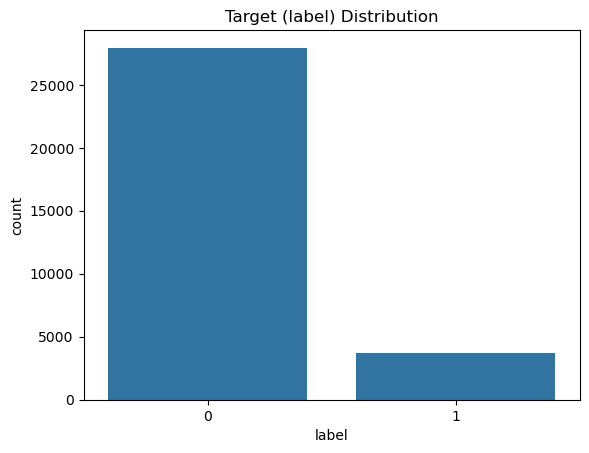

label
0    0.883022
1    0.116978
Name: proportion, dtype: float64


In [3]:
sns.countplot(data=df, x='label')
plt.title("Target (label) Distribution")
plt.show()

print(df['label'].value_counts(normalize=True))


### 수치형 변수

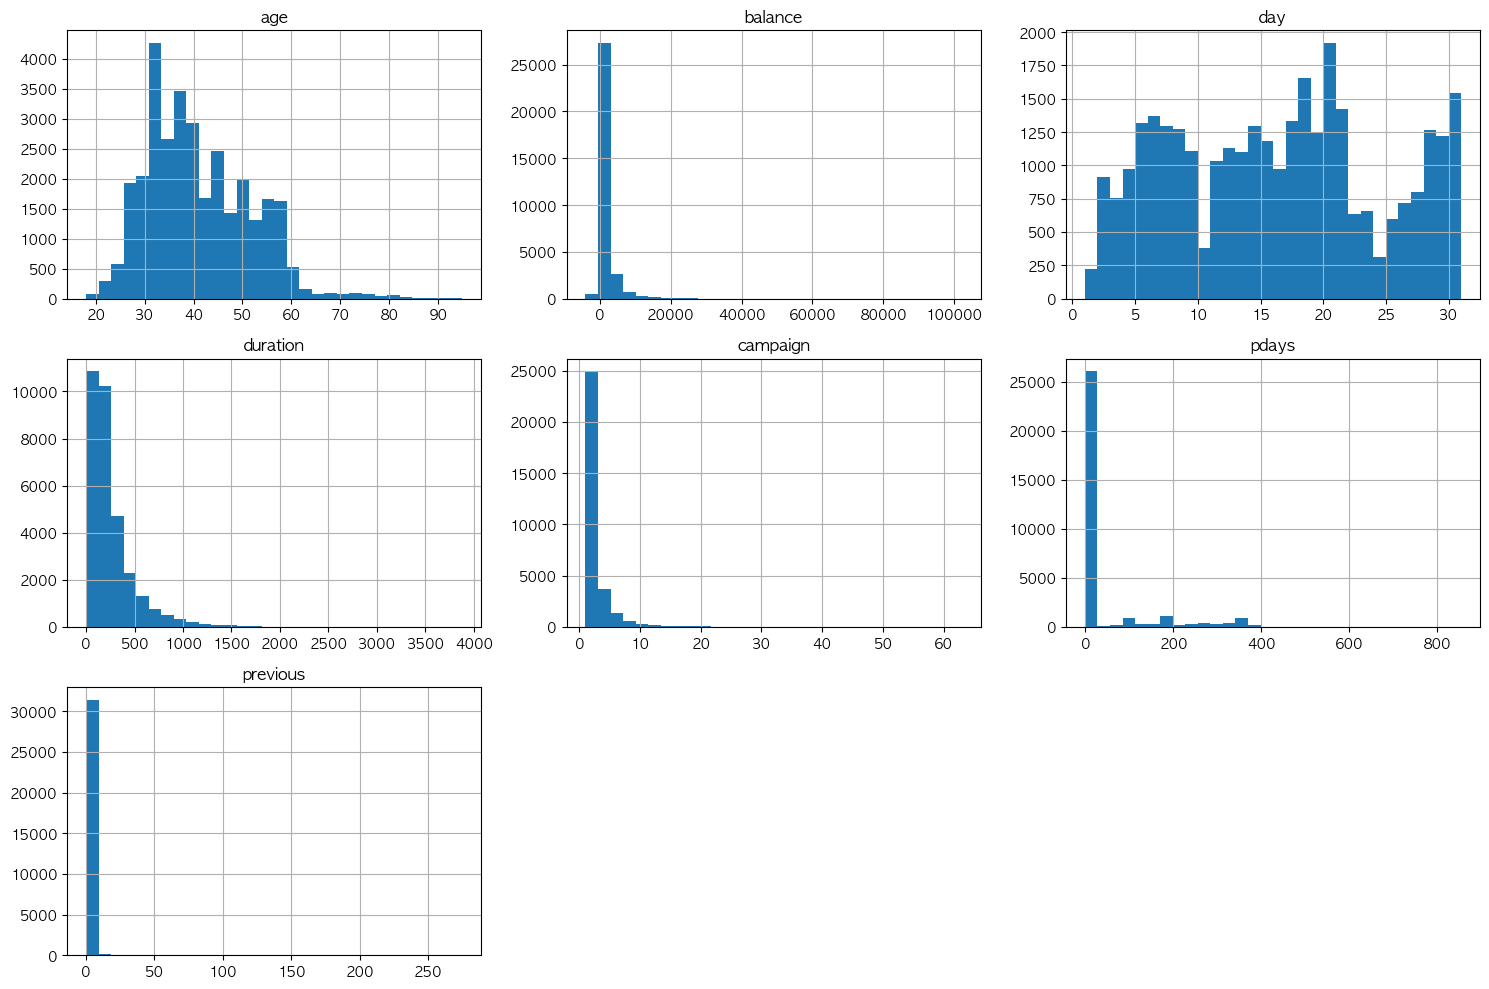

In [5]:
num_col = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

plt.rcParams['font.family'] = 'AppleGothic'
df[num_col].hist(bins=30, figsize=(15, 10))
plt.tight_layout()
plt.show()

In [6]:
df[num_col].describe()

,age,balance,day,duration,campaign,pdays,previous
count,31647.000000,31647.000000,31647.000000,31647.000000,31647.000000,31647.000000,31647.000000
mean,40.916833,1370.050084,15.818277,258.088824,2.752615,40.023604,0.575062
std,10.621773,3122.054996,8.315467,255.737568,3.080952,100.154518,2.433034
min,18.000000,-4057.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,73.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,451.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1418.500000,21.000000,320.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,3881.000000,63.000000,854.000000,275.000000


### 범주형 변수

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/2361515881.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = df[col].value_counts().values, y= df[col].value_counts().index,  palette="pastel")
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/2361515881.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = df[col].value_counts().values, y= df[col].value_counts().index,  palette="pastel")
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/2361515881.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  s

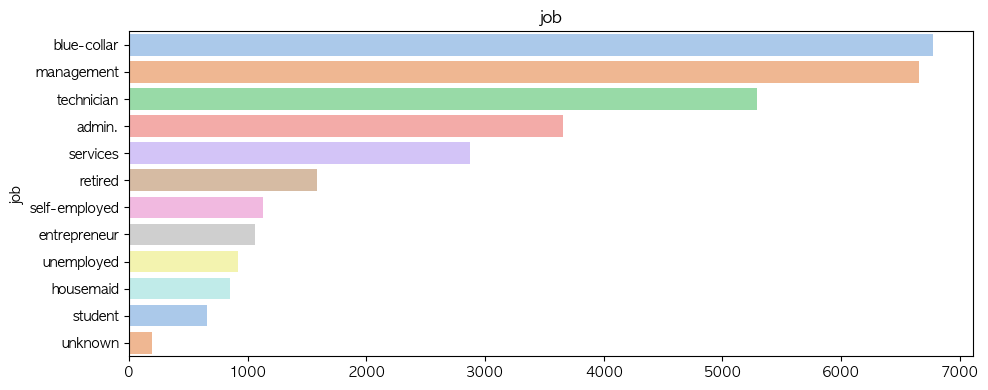

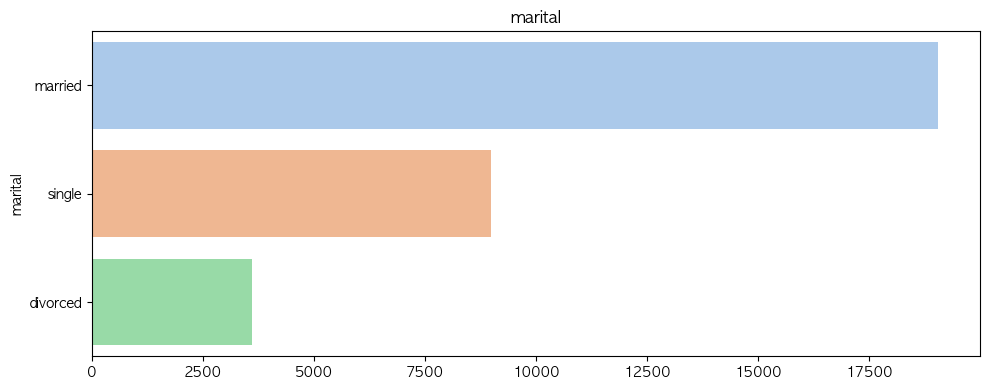

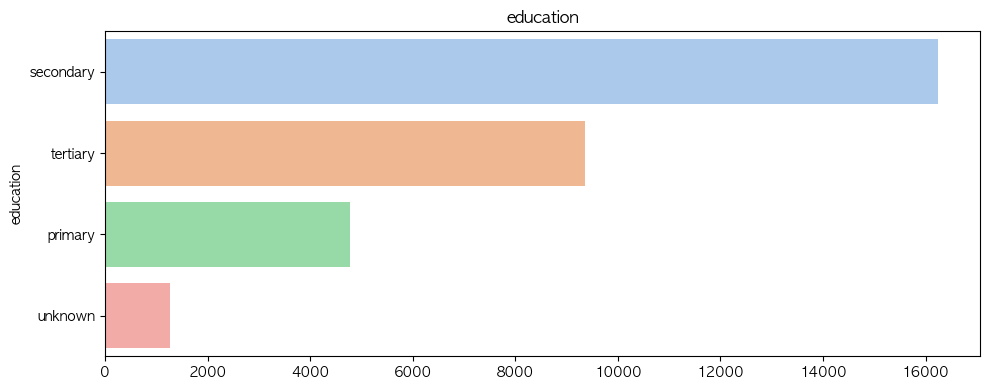

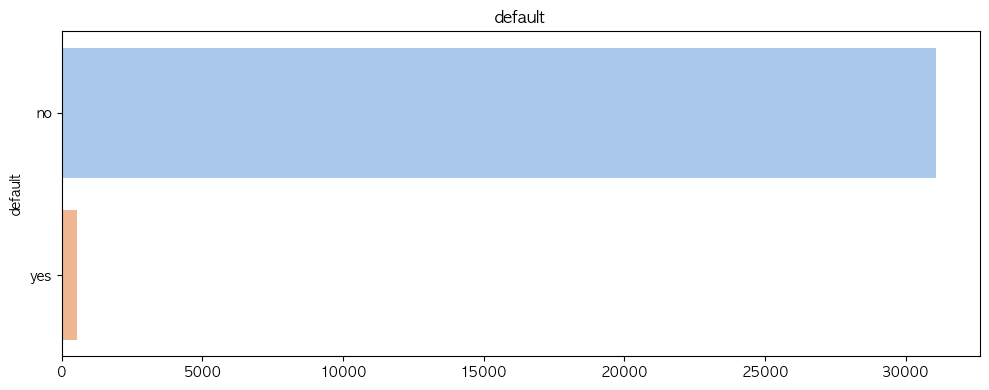

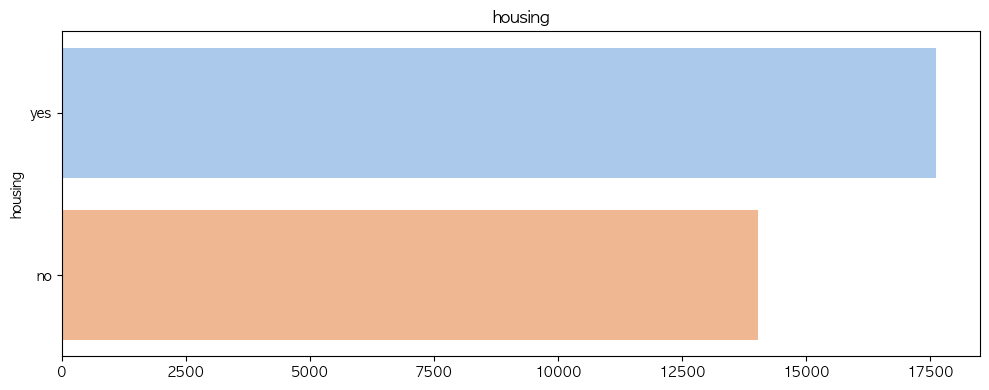

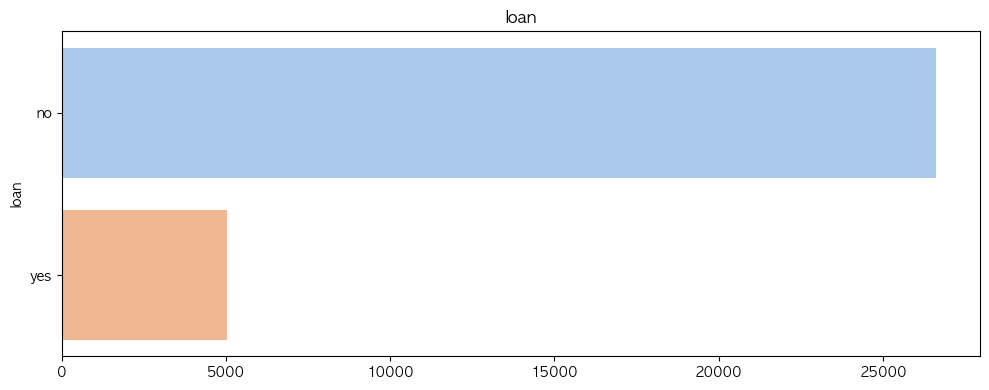

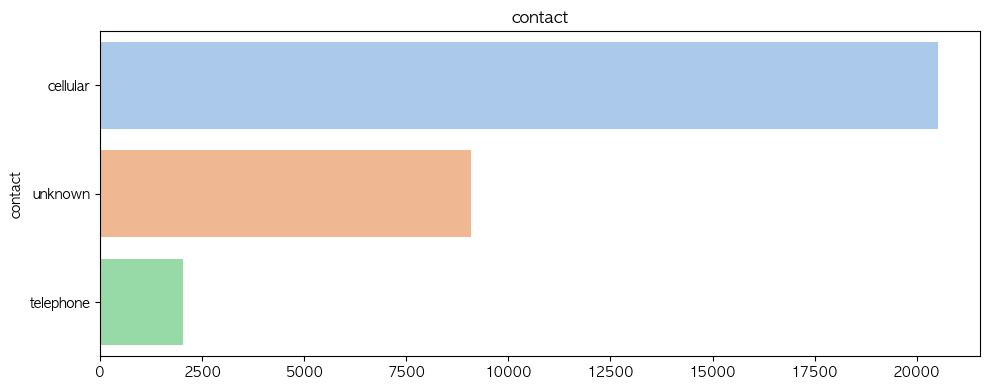

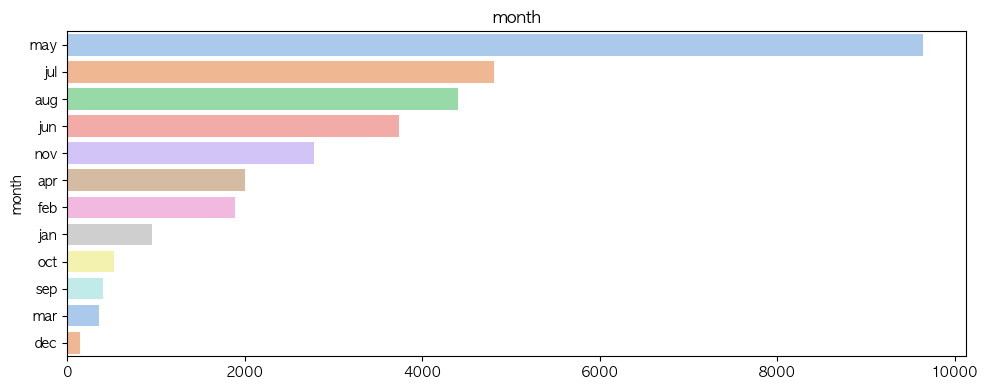

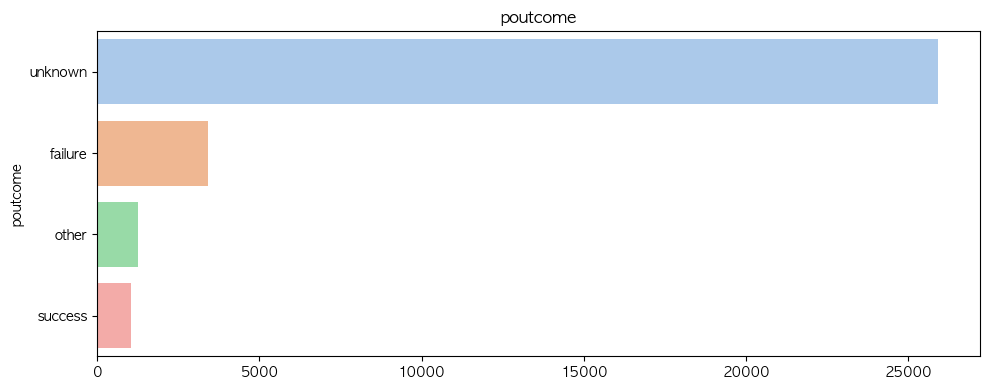

In [12]:
cat_col = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

for col in cat_col:
    plt.figure(figsize=(10,4))
    sns.barplot(x = df[col].value_counts().values, y= df[col].value_counts().index,  palette="pastel")
    plt.title(col)
    plt.tight_layout()


#### 범주형 변수 연관성

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/329823854.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")


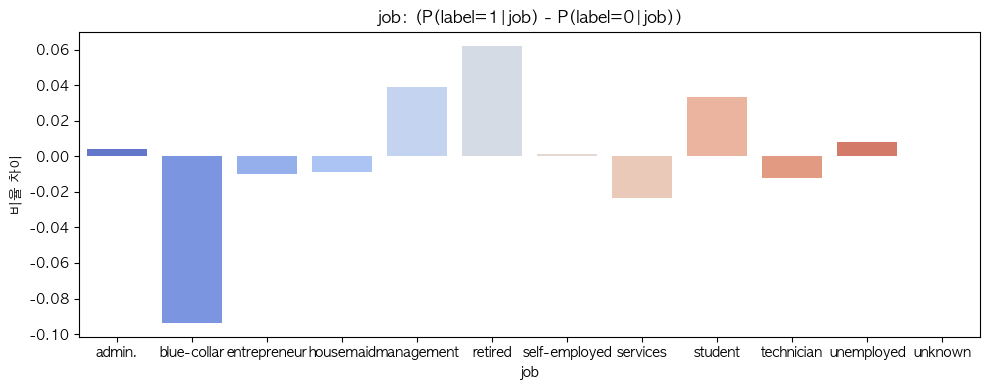

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/329823854.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")


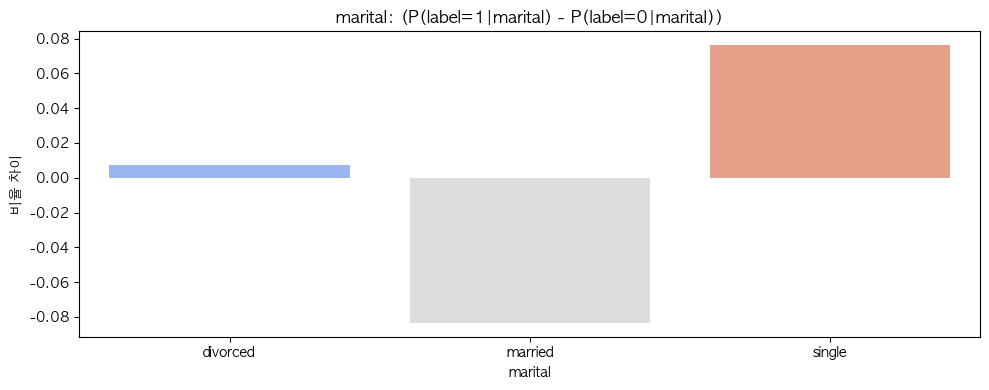

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/329823854.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")


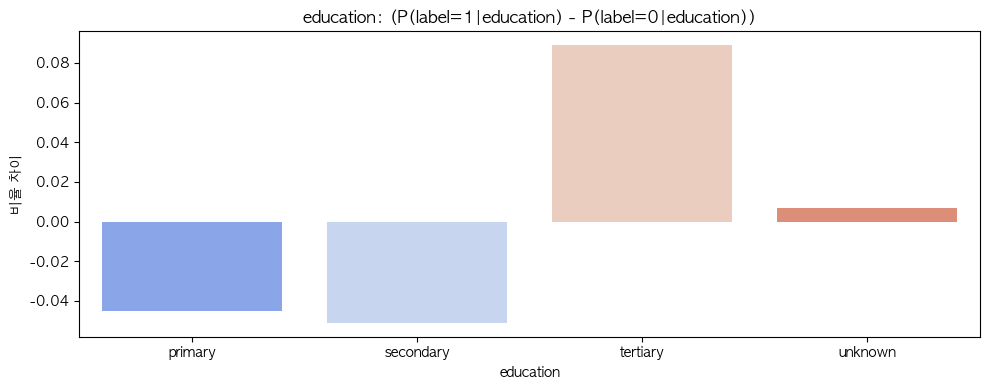

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/329823854.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")


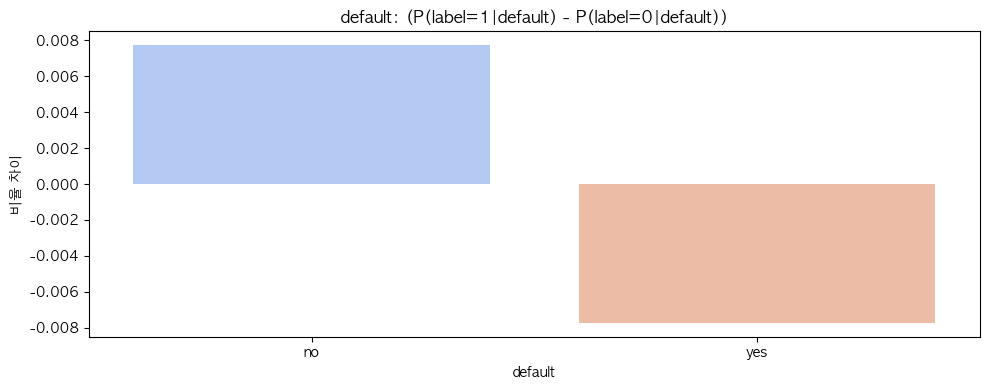

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/329823854.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")


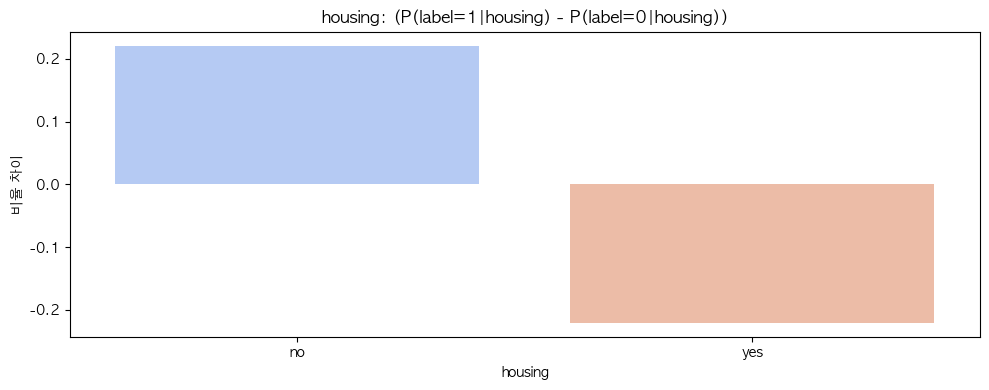

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/329823854.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")


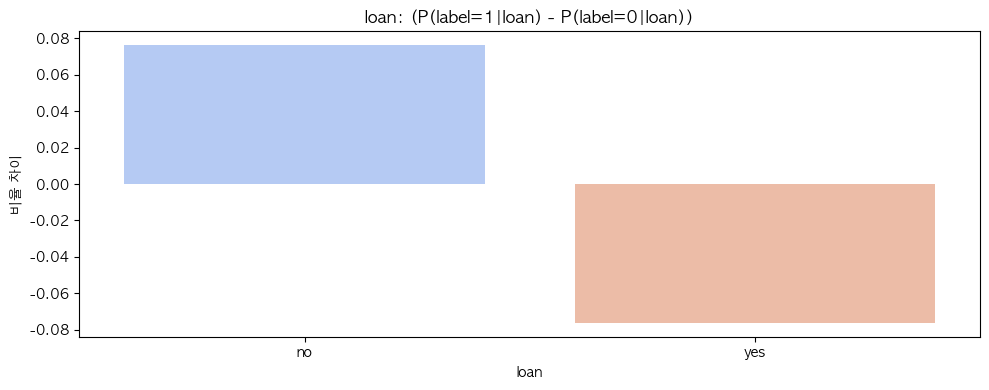

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/329823854.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")


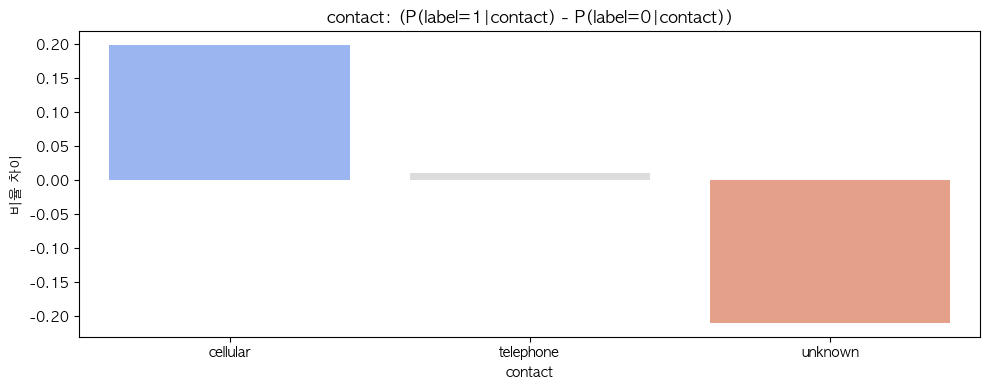

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/329823854.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")


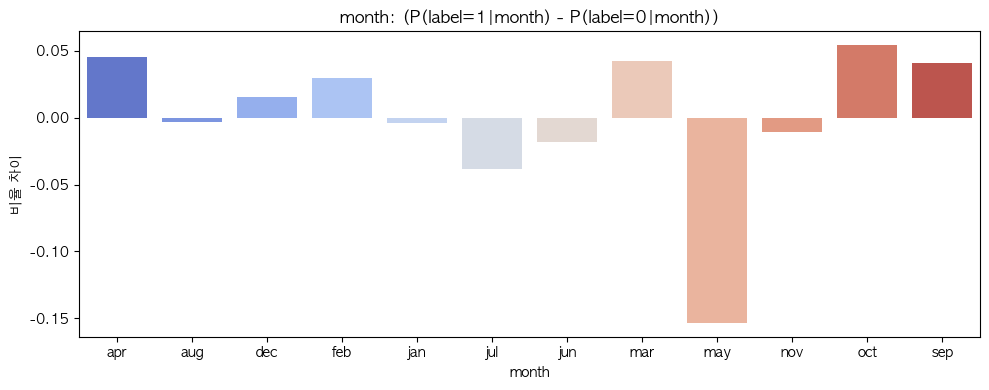

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/329823854.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=all_index, y=diff, palette="coolwarm")


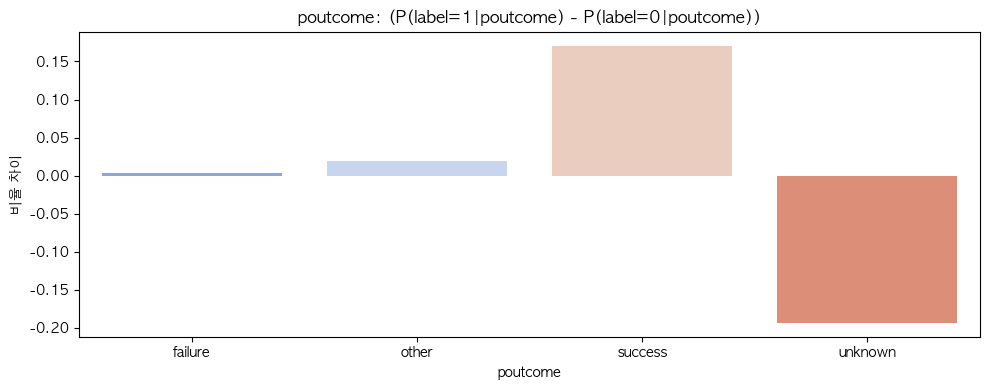

In [19]:
#각 범주별로 label에 따른 빈도 비율 차이를 barplot으로 보기

plt.rcParams['axes.unicode_minus'] = False #마이너스 부호 깨짐 현상 해결용

for col in cat_col:
    plt.figure(figsize=(10,4))
    # 각 label별 count
    pos_counts = df.loc[df['label'] == 1, col].value_counts()
    neg_counts = df.loc[df['label'] == 0, col].value_counts()
    
    # 모든 카테고리 index
    all_index = sorted(set(pos_counts.index).union(set(neg_counts.index)))
    
    # 전체 positive/negative 개수
    freq_pos = (df['label'] == 1).sum()
    freq_neg = (df['label'] == 0).sum()
    
    # 비율 차이 계산
    diff = [
        pos_counts.get(k, 0) / freq_pos - neg_counts.get(k, 0) / freq_neg
        for k in all_index
    ]
    
    # barplot (x=카테고리, y=비율 차이)
    sns.barplot(x=all_index, y=diff, palette="coolwarm")
    plt.title(f"{col}: (P(label=1|{col}) - P(label=0|{col}))")
    plt.xlabel(col)
    plt.ylabel("비율 차이")
    plt.tight_layout()
    plt.show()


#### - 범주형 변수별 가입률

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/3313194603.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df[col], y=df['label'], palette='pastel')


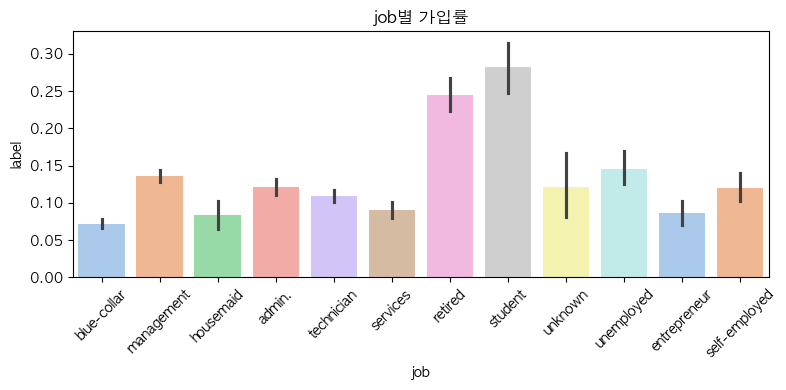

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/3313194603.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df[col], y=df['label'], palette='pastel')


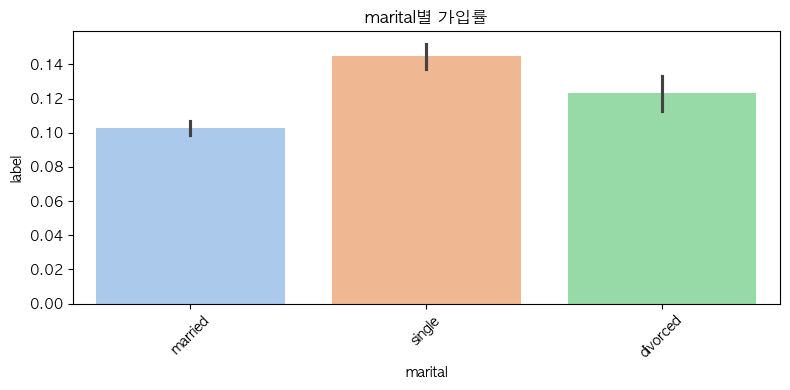

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/3313194603.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df[col], y=df['label'], palette='pastel')


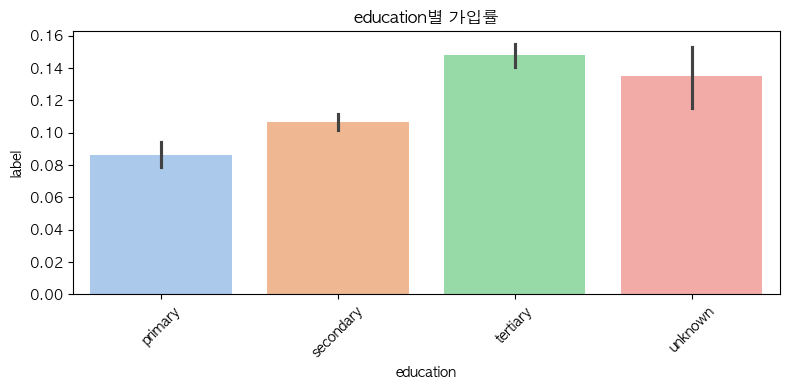

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/3313194603.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df[col], y=df['label'], palette='pastel')


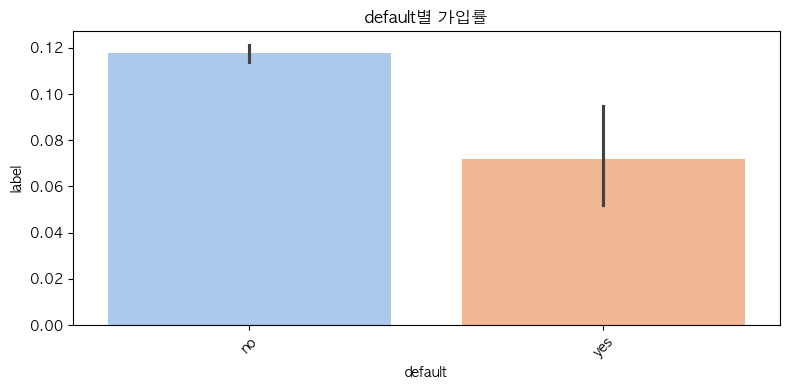

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/3313194603.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df[col], y=df['label'], palette='pastel')


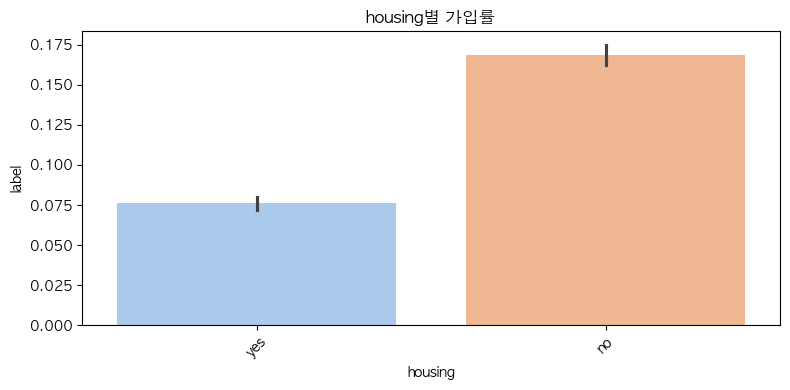

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/3313194603.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df[col], y=df['label'], palette='pastel')


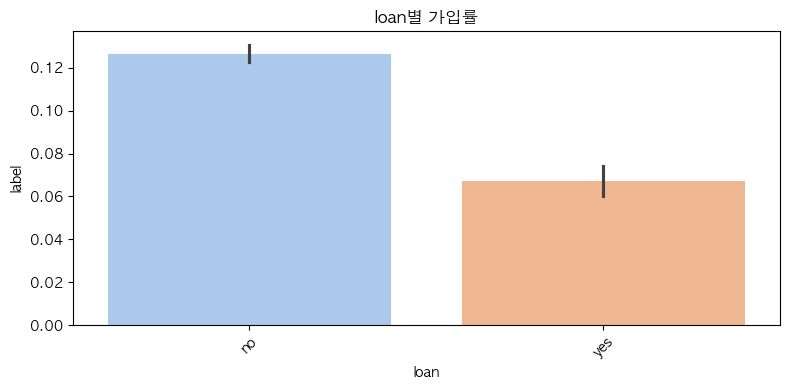

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/3313194603.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df[col], y=df['label'], palette='pastel')


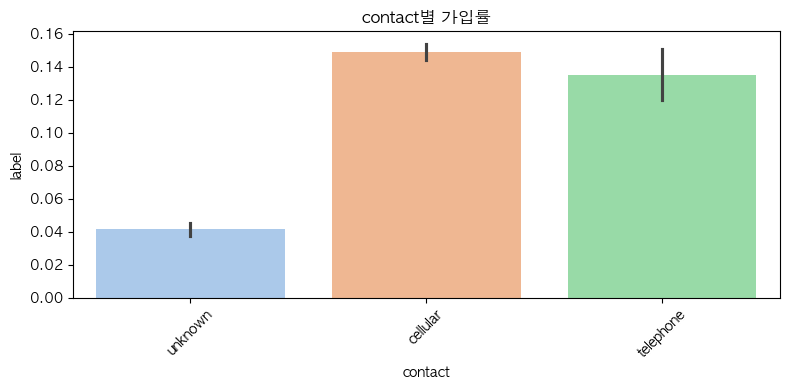

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/3313194603.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df[col], y=df['label'], palette='pastel')


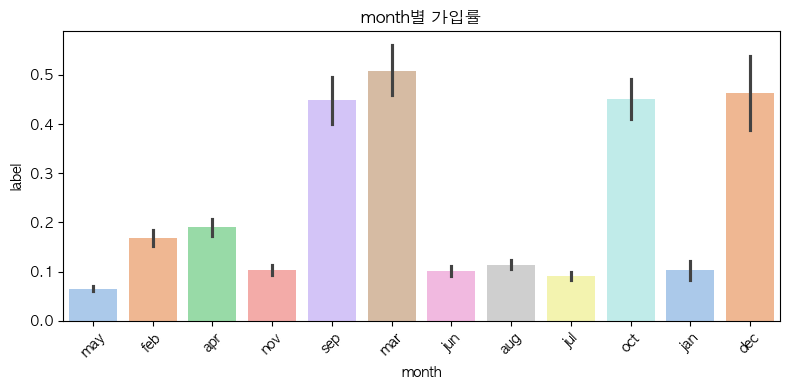

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_18473/3313194603.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df[col], y=df['label'], palette='pastel')


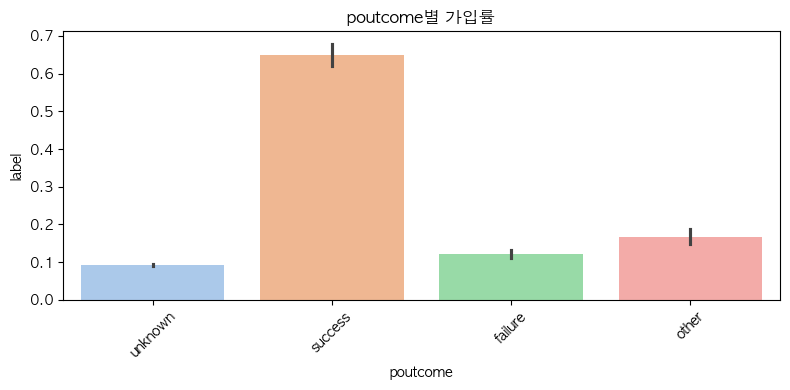

In [20]:
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
for col in cat_cols:
    plt.figure(figsize=(8, 4))
    sns.barplot(x=df[col], y=df['label'], palette='pastel')
    plt.title(f"{col}별 가입률")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


#### OUTLIAR

In [ ]:
def check_num_ouliers(df):
    for col in df.columns:
        if df[col].dtype in ['int64', 'float64']:
            q1 = df[col].quantile(0.25)
            q3 = df[col].quantile(0.75)
            iqr = q3 - q1
            lower_bound = q1 - 1.5 * iqr
            upper_bound = q3 + 1.5 * iqr
            outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
            if not outliers.empty:
                print(f' {col}의 이상치 개수 : {len(outliers)}')

In [ ]:
check_num_ouliers(df)

 age의 이상치 개수 : 337
 balance의 이상치 개수 : 3327
 duration의 이상치 개수 : 2242
 campaign의 이상치 개수 : 2134
 pdays의 이상치 개수 : 5733
 previous의 이상치 개수 : 5733
 label의 이상치 개수 : 3702
